# CS 521 HW4, Bonus Research Question 2: Improve PPO

Open this notebook in Google Colab. The CPU runtime is sufficient: a GPU does not make this notebook faster.

The notebook has a complete implementation of PPO for the CartPole-v1 environment.
In part (a) of Problem 3, you run it and examine two of its parts.
In Bonus Research Question 2, you change the algorithm to improve learning.
Do not change the environment, the training budget (`total_steps`) or the evaluation.

**Environment.** CartPole-v1 gives a reward of +1 for each step. An episode ends when the pole falls
(*termination*) or after 500 steps (*truncation*, a time limit). Thus the maximum return is 500.

In [19]:
# !pip install gymnasium   # Colab has gymnasium. Remove the comment if the import fails.
import copy
import time

import gymnasium as gym
import numpy as np
import torch
import torch.nn as nn
from torch.distributions import Categorical

torch.set_num_threads(1)

CONFIG = dict(
    total_steps=200_000,   # training budget (environment steps). Do not change.
    num_envs=4,            # parallel environments
    num_steps=128,         # steps per environment for each rollout
    lr=2.5e-4,
    anneal_lr=True,        # decrease the learning rate linearly to 0
    gamma=0.99,
    gae_lambda=0.95,
    num_minibatches=4,
    update_epochs=4,
    clip_coef=0.2,
    ent_coef=0.01,
    vf_coef=0.5,
    max_grad_norm=0.5,
    norm_adv=True,         # normalize the advantages in each minibatch
)
SEEDS = [0, 1, 2, 3, 4]

# Environments

`Envs` runs `num_envs` copies of CartPole. When an episode ends, `step` resets that copy automatically.
For each copy, `step` returns:

* `obs`: the next observation. If the episode ended, this is the first observation of the new episode.
* `reward`, `terminated`, `truncated`.
* `final_obs`: the last observation of the episode that ended (`None` if the episode did not end).

`step` also records the return of each finished episode in `self.episodes` as `(global_step, return)`.

In [20]:
class Envs:
    def __init__(self, n, seed):
        self.envs = [gym.make("CartPole-v1") for _ in range(n)]
        self.obs = np.stack([e.reset(seed=seed + i)[0] for i, e in enumerate(self.envs)])
        for i, e in enumerate(self.envs):
            e.action_space.seed(seed + i)
        self.ep_return = np.zeros(n)
        self.global_step = 0
        self.episodes = []

    def step(self, actions):
        rewards, terms, truncs, final_obs = [], [], [], []
        for i, (e, a) in enumerate(zip(self.envs, actions)):
            o, r, term, trunc, _ = e.step(int(a))
            self.ep_return[i] += r
            fo = None
            if term or trunc:
                fo = o
                self.episodes.append((self.global_step + i + 1, self.ep_return[i]))
                self.ep_return[i] = 0
                o, _ = e.reset()
            self.obs[i] = o
            rewards.append(r); terms.append(term); truncs.append(trunc); final_obs.append(fo)
        self.global_step += len(self.envs)
        return self.obs.copy(), np.array(rewards), np.array(terms), np.array(truncs), final_obs

# Agent

The agent has two separate networks with 2 hidden layers of 64 neurons: the actor (policy) and the critic (value).

In [21]:
def layer_init(layer, std=np.sqrt(2), bias=0.0):
    nn.init.orthogonal_(layer.weight, std)
    nn.init.constant_(layer.bias, bias)
    return layer


class Agent(nn.Module):
    def __init__(self, obs_dim=4, n_actions=2):
        super().__init__()
        self.critic = nn.Sequential(
            layer_init(nn.Linear(obs_dim, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 1), std=1.0))
        self.actor = nn.Sequential(
            layer_init(nn.Linear(obs_dim, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, n_actions), std=0.01))

    def get_value(self, x):
        return self.critic(x).squeeze(-1)

    def get_action_and_value(self, x, action=None):
        dist = Categorical(logits=self.actor(x))
        if action is None:
            action = dist.sample()
        return action, dist.log_prob(action), dist.entropy(), self.get_value(x)

# PPO

`compute_gae` calculates the advantages with generalized advantage estimation (GAE).
`ppo_update` does `update_epochs` passes over the rollout with the clipped surrogate objective.
`train_ppo(seed, cfg)` trains one agent and returns the agent and the list of `(global_step, return)` of the
training episodes.

In [22]:
def compute_gae(rewards, values, dones, next_value, next_done, gamma, lam):
    # rewards, values, dones: (num_steps, num_envs). dones[t] = 1 if the episode ended at step t - 1,
    # thus obs[t] is the first observation of a new episode.
    T = len(rewards)
    adv = torch.zeros_like(rewards)
    last = 0
    for t in reversed(range(T)):
        not_done = 1.0 - (next_done if t == T - 1 else dones[t + 1])
        nv = next_value if t == T - 1 else values[t + 1]
        delta = rewards[t] + gamma * nv * not_done - values[t]
        last = delta + gamma * lam * not_done * last
        adv[t] = last
    return adv, adv + values


def ppo_update(agent, opt, b, cfg):
    n = len(b["obs"])
    mb_size = n // cfg["num_minibatches"]
    stats = []
    for _ in range(cfg["update_epochs"]):
        idx = torch.randperm(n)
        for start in range(0, n, mb_size):
            mb = idx[start:start + mb_size]
            _, logp, ent, v = agent.get_action_and_value(b["obs"][mb], b["actions"][mb])
            ratio = (logp - b["logp"][mb]).exp()
            adv = b["adv"][mb]
            if cfg["norm_adv"]:
                adv = (adv - adv.mean()) / (adv.std() + 1e-8)
            pg_loss = torch.max(-adv * ratio,
                                -adv * ratio.clamp(1 - cfg["clip_coef"], 1 + cfg["clip_coef"])).mean()
            v_loss = 0.5 * ((v - b["returns"][mb]) ** 2).mean()
            loss = pg_loss - cfg["ent_coef"] * ent.mean() + cfg["vf_coef"] * v_loss
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(agent.parameters(), cfg["max_grad_norm"])
            opt.step()
            stats.append(((ratio - 1).abs() > cfg["clip_coef"]).float().mean().item())
    return {"clip_frac": float(np.mean(stats))}


def train_ppo(seed, cfg=None, verbose=False):
    cfg = {**CONFIG, **(cfg or {})}
    torch.manual_seed(seed)
    np.random.seed(seed)
    envs = Envs(cfg["num_envs"], seed)
    agent = Agent()
    opt = torch.optim.Adam(agent.parameters(), lr=cfg["lr"], eps=1e-5)
    N, T = cfg["num_envs"], cfg["num_steps"]
    n_updates = cfg["total_steps"] // (N * T)
    obs = torch.zeros(T, N, 4); actions = torch.zeros(T, N, dtype=torch.long)
    logps = torch.zeros(T, N); rewards = torch.zeros(T, N); dones = torch.zeros(T, N); values = torch.zeros(T, N)
    next_obs = torch.tensor(envs.obs, dtype=torch.float32)
    next_done = torch.zeros(N)
    start = time.time()
    for update in range(n_updates):
        if cfg["anneal_lr"]:
            opt.param_groups[0]["lr"] = cfg["lr"] * (1 - update / n_updates)
        for t in range(T):
            obs[t], dones[t] = next_obs, next_done
            with torch.no_grad():
                a, logp, _, v = agent.get_action_and_value(next_obs)
            actions[t], logps[t], values[t] = a, logp, v
            o, r, term, trunc, _ = envs.step(a.numpy())
            rewards[t] = torch.tensor(r, dtype=torch.float32)
            next_obs = torch.tensor(o, dtype=torch.float32)
            next_done = torch.tensor(term | trunc, dtype=torch.float32)
        with torch.no_grad():
            adv, returns = compute_gae(rewards, values, dones, agent.get_value(next_obs), next_done,
                                       cfg["gamma"], cfg["gae_lambda"])
        b = {"obs": obs.reshape(-1, 4), "actions": actions.reshape(-1), "logp": logps.reshape(-1),
             "adv": adv.reshape(-1), "returns": returns.reshape(-1)}
        stats = ppo_update(agent, opt, b, cfg)
        if verbose and (update + 1) % 20 == 0:
            recent = [r for _, r in envs.episodes[-10:]]
            print(f"step {envs.global_step:6d}  mean return (last 10) {np.mean(recent):6.1f}  "
                  f"clip frac {stats['clip_frac']:.3f}")
    return agent, envs.episodes, time.time() - start

# Evaluation

`evaluate_policy` runs the greedy policy (the action with the highest probability) for 20 episodes with fixed seeds.
`summarize(runs)` gives these metrics for a list of runs (one run for each seed):

* `auc`: the mean of the learning curve over the training budget. The learning curve is the mean return of the last
  10 training episodes, at 100 equally spaced steps. A higher value means faster learning.
* `steps_to_475`: the first step where the mean return of the last 10 training episodes is at least 475.
  If a run does not get there, we use `total_steps`.
* `final`: the return of the greedy policy at the end of training.

`plot_curves` plots the mean learning curve over the seeds. Use these functions for all the numbers in your report.

In [23]:
@torch.no_grad()
def evaluate_policy(agent, episodes=20, seed=10_000):
    env = gym.make("CartPole-v1")
    total = 0.0
    for k in range(episodes):
        o, _ = env.reset(seed=seed + k)
        done = False
        while not done:
            a = agent.actor(torch.tensor(o, dtype=torch.float32)).argmax().item()
            o, r, term, trunc, _ = env.step(a)
            total += r
            done = term or trunc
    return total / episodes


def learning_curve(episodes, total_steps=CONFIG["total_steps"], points=100, window=10):
    steps = np.array([s for s, _ in episodes])
    rets = np.array([r for _, r in episodes])
    grid = np.linspace(total_steps / points, total_steps, points)
    curve = []
    for g in grid:
        r = rets[steps <= g][-window:]
        curve.append(r.mean() if len(r) else 0.0)
    return grid, np.array(curve)


def steps_to(episodes, target=475, window=10, total_steps=CONFIG["total_steps"]):
    rets = [r for _, r in episodes]
    for k in range(window, len(episodes) + 1):
        if np.mean(rets[k - window:k]) >= target:
            return episodes[k - 1][0]
    return total_steps


def run_seeds(cfg=None, seeds=SEEDS, train_fn=None, verbose=True):
    train_fn = train_fn or train_ppo
    runs = []
    for s in seeds:
        agent, episodes, sec = train_fn(s, cfg)
        runs.append({"seed": s, "episodes": episodes, "time": sec, "final": evaluate_policy(agent)})
        if verbose:
            print(f"seed {s}: auc {learning_curve(episodes)[1].mean():6.1f}  steps_to_475 {steps_to(episodes):6d}  "
                  f"final {runs[-1]['final']:6.1f}  time {sec:5.1f} s")
    return runs


def summarize(runs, name=""):
    auc = [learning_curve(r["episodes"])[1].mean() for r in runs]
    st = [steps_to(r["episodes"]) for r in runs]
    fin = [r["final"] for r in runs]
    res = {"name": name, "auc": np.mean(auc), "auc_std": np.std(auc), "steps_to_475": np.mean(st),
           "solved": sum(s < CONFIG["total_steps"] for s in st), "final": np.mean(fin),
           "final_std": np.std(fin), "time": np.mean([r["time"] for r in runs])}
    print(f"{name:<24} auc {res['auc']:6.1f} +- {res['auc_std']:5.1f}  steps_to_475 {res['steps_to_475']:8.0f} "
          f"({res['solved']}/{len(runs)} runs)  final {res['final']:6.1f} +- {res['final_std']:5.1f}  "
          f"time {res['time']:5.1f} s")
    return res


def plot_curves(named_runs):
    import matplotlib.pyplot as plt
    for name, runs in named_runs.items():
        curves = np.stack([learning_curve(r["episodes"])[1] for r in runs])
        grid = learning_curve(runs[0]["episodes"])[0]
        m, s = curves.mean(0), curves.std(0)
        plt.plot(grid, m, label=name)
        plt.fill_between(grid, m - s, m + s, alpha=0.2)
    plt.xlabel("environment steps"); plt.ylabel("mean return (last 10 episodes)"); plt.legend(); plt.show()

# (i) Idea: clip the gradients of the actor and the critic separately

**Observation.** `ppo_update` clips the gradient norm of all parameters together to `max_grad_norm = 0.5`. The actor and the critic are separate networks, but they share one loss and one clipping step. The value loss is large (the returns reach about 100 with $\gamma = 0.99$), so the critic gradient is usually much larger than the actor gradient, and the common clipping factor $0.5 / \|g\|$ is set almost only by the critic. The actor gradient is then scaled down by a factor that follows the critic loss and changes from one minibatch to the next.

**Method.** Clip the actor gradient and the critic gradient separately, each to `max_grad_norm`:

$$g_\pi \leftarrow g_\pi \cdot \min\left(1, \tfrac{c}{\|g_\pi\|}\right), \qquad g_V \leftarrow g_V \cdot \min\left(1, \tfrac{c}{\|g_V\|}\right).$$

The losses, the data and all hyperparameters are the same as in PPO. Each network is clipped by its own norm, so a large value error does not change the size of the policy update.

**Why it should help.** The policy update then depends on the policy gradient alone, and the critic keeps its safeguard against large steps. The implementation details of PPO that matter for performance, including gradient clipping, are studied in Engstrom et al., *Implementation Matters in Deep Policy Gradients* (ICLR 2020) and Andrychowicz et al., *What Matters in On-Policy Reinforcement Learning?* (ICLR 2021). The question here is how the clipping interacts with the split between actor and critic. I did not find a source for this exact change, so I treat it as my own and test it.

**Other change in the notebook.** The option `trunc_bootstrap` treats the 500-step time limit as a truncation and bootstraps the reward with $\gamma V(s_{final})$ instead of treating the state as terminal (Pardo et al., *Time Limits in Reinforcement Learning*, ICML 2018). It is off by default and used in the ablation.

# (ii) Implementation

In [24]:
OPTIONS = {"sep_clip": True, "clip_critic": True, "trunc_bootstrap": False, "log_grads": False}
GRAD_LOG = []


def my_ppo_update(agent, opt, b, cfg, options):
    n = len(b["obs"])
    mb_size = n // cfg["num_minibatches"]
    inf = float("inf")
    for _ in range(cfg["update_epochs"]):
        idx = torch.randperm(n)
        for start in range(0, n, mb_size):
            mb = idx[start:start + mb_size]
            _, logp, ent, v = agent.get_action_and_value(b["obs"][mb], b["actions"][mb])
            ratio = (logp - b["logp"][mb]).exp()
            adv = b["adv"][mb]
            if cfg["norm_adv"]:
                adv = (adv - adv.mean()) / (adv.std() + 1e-8)
            pg_loss = torch.max(-adv * ratio,
                                -adv * ratio.clamp(1 - cfg["clip_coef"], 1 + cfg["clip_coef"])).mean()
            v_loss = 0.5 * ((v - b["returns"][mb]) ** 2).mean()
            loss = pg_loss - cfg["ent_coef"] * ent.mean() + cfg["vf_coef"] * v_loss
            opt.zero_grad()
            loss.backward()
            sep, c = options["sep_clip"], cfg["max_grad_norm"]
            a_norm = nn.utils.clip_grad_norm_(agent.actor.parameters(), c if sep else inf)
            c_norm = nn.utils.clip_grad_norm_(agent.critic.parameters(), c if sep and options["clip_critic"] else inf)
            if not sep:
                nn.utils.clip_grad_norm_(agent.parameters(), c)
            if options["log_grads"]:
                GRAD_LOG.append((a_norm.item(), c_norm.item()))
            opt.step()


def my_train_ppo(seed, cfg=None, verbose=False, options=None):
    options = {**OPTIONS, **(options or {})}
    cfg = {**CONFIG, **(cfg or {})}
    torch.manual_seed(seed)
    np.random.seed(seed)
    envs = Envs(cfg["num_envs"], seed)
    agent = Agent()
    opt = torch.optim.Adam(agent.parameters(), lr=cfg["lr"], eps=1e-5)
    N, T = cfg["num_envs"], cfg["num_steps"]
    n_updates = cfg["total_steps"] // (N * T)
    obs = torch.zeros(T, N, 4); actions = torch.zeros(T, N, dtype=torch.long)
    logps = torch.zeros(T, N); rewards = torch.zeros(T, N); dones = torch.zeros(T, N); values = torch.zeros(T, N)
    next_obs = torch.tensor(envs.obs, dtype=torch.float32)
    next_done = torch.zeros(N)
    start = time.time()
    for update in range(n_updates):
        if cfg["anneal_lr"]:
            opt.param_groups[0]["lr"] = cfg["lr"] * (1 - update / n_updates)
        for t in range(T):
            obs[t], dones[t] = next_obs, next_done
            with torch.no_grad():
                a, logp, _, v = agent.get_action_and_value(next_obs)
            actions[t], logps[t], values[t] = a, logp, v
            o, r, term, trunc, final_obs = envs.step(a.numpy())
            r = torch.tensor(r, dtype=torch.float32)
            if options["trunc_bootstrap"]:
                for i in range(N):
                    if trunc[i] and not term[i] and final_obs[i] is not None:
                        with torch.no_grad():
                            r[i] += cfg["gamma"] * agent.get_value(torch.tensor(final_obs[i], dtype=torch.float32))
            rewards[t] = r
            next_obs = torch.tensor(o, dtype=torch.float32)
            next_done = torch.tensor(term | trunc, dtype=torch.float32)
        with torch.no_grad():
            adv, returns = compute_gae(rewards, values, dones, agent.get_value(next_obs), next_done,
                                       cfg["gamma"], cfg["gae_lambda"])
        b = {"obs": obs.reshape(-1, 4), "actions": actions.reshape(-1), "logp": logps.reshape(-1),
             "adv": adv.reshape(-1), "returns": returns.reshape(-1)}
        my_ppo_update(agent, opt, b, cfg, options)
        if verbose and (update + 1) % 20 == 0:
            recent = [r for _, r in envs.episodes[-10:]]
            print(f"step {envs.global_step:6d}  mean return (last 10) {np.mean(recent):6.1f}")
    return agent, envs.episodes, time.time() - start

# (iii) Results

Five seeds for PPO and for the new method, with the metrics and the learning curves of the starter functions.

seed 0: auc  312.3  steps_to_475 147774  final  500.0  time  74.8 s
seed 1: auc  244.2  steps_to_475  95166  final  294.8  time  74.2 s
seed 2: auc  329.1  steps_to_475  76370  final  495.1  time  72.2 s
seed 3: auc  340.3  steps_to_475  69435  final  453.4  time  73.2 s
seed 4: auc  361.6  steps_to_475  99675  final  500.0  time  71.9 s
seed 0: auc  409.8  steps_to_475  45398  final  500.0  time  73.1 s
seed 1: auc  387.4  steps_to_475  95581  final  500.0  time  73.8 s
seed 2: auc  387.3  steps_to_475  55836  final  500.0  time  72.8 s
seed 3: auc  276.3  steps_to_475  32351  final  437.6  time  75.3 s
seed 4: auc  375.1  steps_to_475  70394  final  500.0  time  73.6 s
PPO                      auc  317.5 +-  40.0  steps_to_475    97684 (5/5 runs)  final  448.6 +-  78.9  time  73.3 s
separate clipping (mine) auc  367.2 +-  46.8  steps_to_475    59912 (5/5 runs)  final  487.5 +-  25.0  time  73.7 s


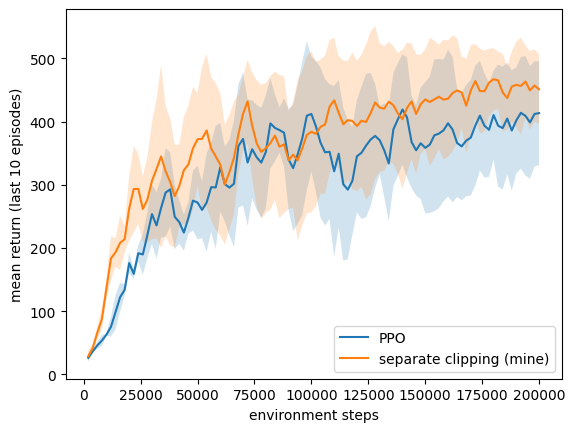

In [16]:
all_runs = {"PPO": run_seeds(),
            "separate clipping (mine)": run_seeds(train_fn=my_train_ppo)}
results = {name: summarize(runs, name) for name, runs in all_runs.items()}
plot_curves(all_runs)

# (iv) Ablation

Three changes to the method, one at a time:

* `no gradient clipping`: PPO with `max_grad_norm` set to infinity. This tests if the clipping itself limits PPO.
* `critic not clipped`: the actor is clipped alone and the critic is not clipped.
* `separate clipping + time-limit bootstrapping`: the method plus the bootstrapping of the time limit.

seed 0: auc  387.1  steps_to_475  91975  final  500.0  time  74.1 s
seed 1: auc  316.4  steps_to_475  76546  final  500.0  time  72.5 s
seed 2: auc  399.6  steps_to_475  54858  final  500.0  time  73.5 s
seed 3: auc  366.9  steps_to_475  86986  final  500.0  time  73.9 s
seed 4: auc  345.4  steps_to_475 104773  final  477.2  time  75.6 s
seed 0: auc  279.8  steps_to_475 200000  final  498.6  time  73.4 s
seed 1: auc  395.1  steps_to_475  70542  final  442.6  time  75.4 s
seed 2: auc  400.2  steps_to_475  47827  final  491.1  time  72.6 s
seed 3: auc  291.3  steps_to_475  61996  final  492.9  time  73.1 s
seed 4: auc  365.4  steps_to_475 108237  final  500.0  time  72.7 s
seed 0: auc  248.3  steps_to_475  92963  final  230.7  time  73.4 s
seed 1: auc  360.0  steps_to_475 106787  final  500.0  time  74.7 s
seed 2: auc  386.3  steps_to_475  47128  final  500.0  time  79.6 s
seed 3: auc  371.9  steps_to_475  32351  final  500.0  time  74.9 s
seed 4: auc  394.1  steps_to_475  82570  final  

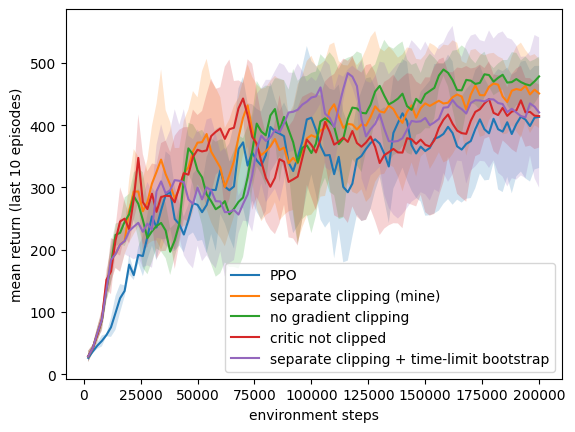

In [17]:
ablations = {
    "no gradient clipping": run_seeds({"max_grad_norm": float("inf")}),
    "critic not clipped": run_seeds(train_fn=lambda s, c: my_train_ppo(s, c, options={"clip_critic": False})),
    "separate clipping + time-limit bootstrap": run_seeds(train_fn=lambda s, c: my_train_ppo(s, c, options={"trunc_bootstrap": True})),
}
ablation_results = {name: summarize(runs, name) for name, runs in ablations.items()}
plot_curves({"PPO": all_runs["PPO"], "separate clipping (mine)": all_runs["separate clipping (mine)"], **ablations})

# (v) Analysis

## Size of the gradients

For PPO (common clipping), the norm of the actor gradient and of the critic gradient before clipping, for each minibatch step of one run, and the factor by which the common clipping multiplies the actor gradient. The run is split in three equal parts.

In [18]:
GRAD_LOG.clear()
_ = my_train_ppo(0, options={"sep_clip": False, "log_grads": True})
g = np.array(GRAD_LOG)
scale = np.minimum(1.0, CONFIG["max_grad_norm"] / np.sqrt(g[:, 0] ** 2 + g[:, 1] ** 2))
print(f"{'part':>5s} {'actor norm':>11s} {'critic norm':>12s} {'mean factor on actor':>21s} {'steps with factor < 0.5':>24s}")
for k, part in enumerate(np.array_split(np.arange(len(g)), 3)):
    print(f"{k + 1:5d} {g[part, 0].mean():11.3f} {g[part, 1].mean():12.3f} {scale[part].mean():21.3f} {(scale[part] < 0.5).mean():24.2f}")

 part  actor norm  critic norm  mean factor on actor  steps with factor < 0.5
    1       0.219       32.246                 0.018                     1.00
    2       0.289       16.313                 0.069                     0.98
    3       0.227       20.128                 0.054                     0.98


## Discussion

Separate clipping of the actor and the critic gradient improves PPO on all three metrics (seeds 0 to 4): auc 367.2 against 317.5, steps to 475 of 59,912 against 97,684, and final return 487.5 ± 25.0 against 448.6 ± 78.9. Training time is the same.

The gradient sizes explain the change. The critic gradient (norm 16 to 32) is 50 to 150 times larger than the actor gradient (norm 0.2 to 0.3), so the common clipping shrinks the actor gradient to 2% to 7% of its size on 98% to 100% of the steps. Clipping each network by its own norm leaves the actor gradient almost unchanged.

The ablation limits the claim. PPO without any gradient clipping reaches auc 363.1 and a final return of 495.4 ± 9.1, so separate clipping is not better than no clipping here. Leaving the critic unclipped (auc 346.4) and adding time-limit bootstrapping (auc 352.1, final return 446.1 ± 107.7) do not help. The auc differences between the method and the three ablations are 21 points or less, below the seed standard deviations of 30 to 53, so with 5 seeds the ranking among them is not settled. The auc gain over PPO is about 1.8 standard errors. The gradient diagnostic comes from one run, and I did not separate the effect of the changing clipping factor from the effect of the small gradient size under Adam.